# 09. Slim card table for the public app

The full card table (`data/cards_2025-26.csv`) has 154 columns, including raw MoneyPuck situation stats (`ev_`, `pp_`, `pk_`, `all_`). That data stays private, so `data/` is gitignored.

The Streamlit app only needs what the card actually draws. `player_card.export_app_table` keeps just those columns, building the list from `SECTIONS` and `EDGE_ROWS` (skipping `HIDDEN_ROWS`) so it stays in sync with the card. The result goes to `app_data/cards_2025-26.csv`, which is committed and read by `app.py`.

## 1. Setup

In [4]:
import sys
from pathlib import Path

import pandas as pd

sys.path.append("../src")
from player_card import app_columns, export_app_table

FULL_PATH = Path("../data/cards_2025-26.csv")
APP_PATH = Path("../app_data/cards_2025-26.csv")

## 2. Write the slim table

In [5]:
cards = pd.read_csv(FULL_PATH)
slim = export_app_table(cards, APP_PATH)
print(f"Full table: {cards.shape}   Slim table: {slim.shape}")

Full table: (940, 154)   Slim table: (940, 57)


## 3. Checks

Each `assert` stops the notebook with an error if something is wrong.

In [6]:
# No raw MoneyPuck situation columns, except ev_rel_xga_60 (shown on the card)
raw = [c for c in slim.columns if c.startswith(("ev_", "pp_", "pk_", "all_")) and c != "ev_rel_xga_60"]
assert not raw, f"Raw situation columns in slim table: {raw}"

# Hidden card rows are left out
assert "oz_pct_ev" not in slim.columns and "pct_oz_pct_ev" not in slim.columns

# playerId comes first and identifies each row
assert slim.columns[0] == "playerId"
assert slim["playerId"].is_unique

# Same columns as app_columns(), same players as the full table
assert list(slim.columns) == app_columns()
assert len(slim) == len(cards)

print("All checks passed.", slim.shape)
print(list(slim.columns))

All checks passed. (940, 57)
['playerId', 'name', 'team', 'position', 'pos_group', 'age', 'draft_text', 'qualified', 'games_played', 'goals', 'assists', 'points', 'toi_per_gp', 'war_rank', 'war_rank_pos', 'war', 'pct_war', 'off_war', 'pct_off_war', 'def_war', 'pct_def_war', 'other_war', 'pct_other_war', 'g_60', 'pct_g_60', 'ixg_60', 'pct_ixg_60', 'sog_60', 'pct_sog_60', 'fin_60', 'pct_fin_60', 'a1_60', 'pct_a1_60', 'a_60', 'pct_a_60', 'pts_60', 'pct_pts_60', 'ev_rel_xga_60', 'pct_ev_rel_xga_60', 'onice_xga_60', 'pct_onice_xga_60', 'hits_60', 'pct_hits_60', 'blk_60', 'pct_blk_60', 'take_60', 'pct_take_60', 'give_60', 'pct_give_60', 'pend_60', 'pct_pend_60', 'top_speed', 'pct_top_speed', 'bursts_20_60', 'pct_bursts_20_60', 'shot_speed', 'pct_shot_speed']


## 4. README card

Redraw Seider's card from the slim table, so the README image matches the app (no offensive zone time row).

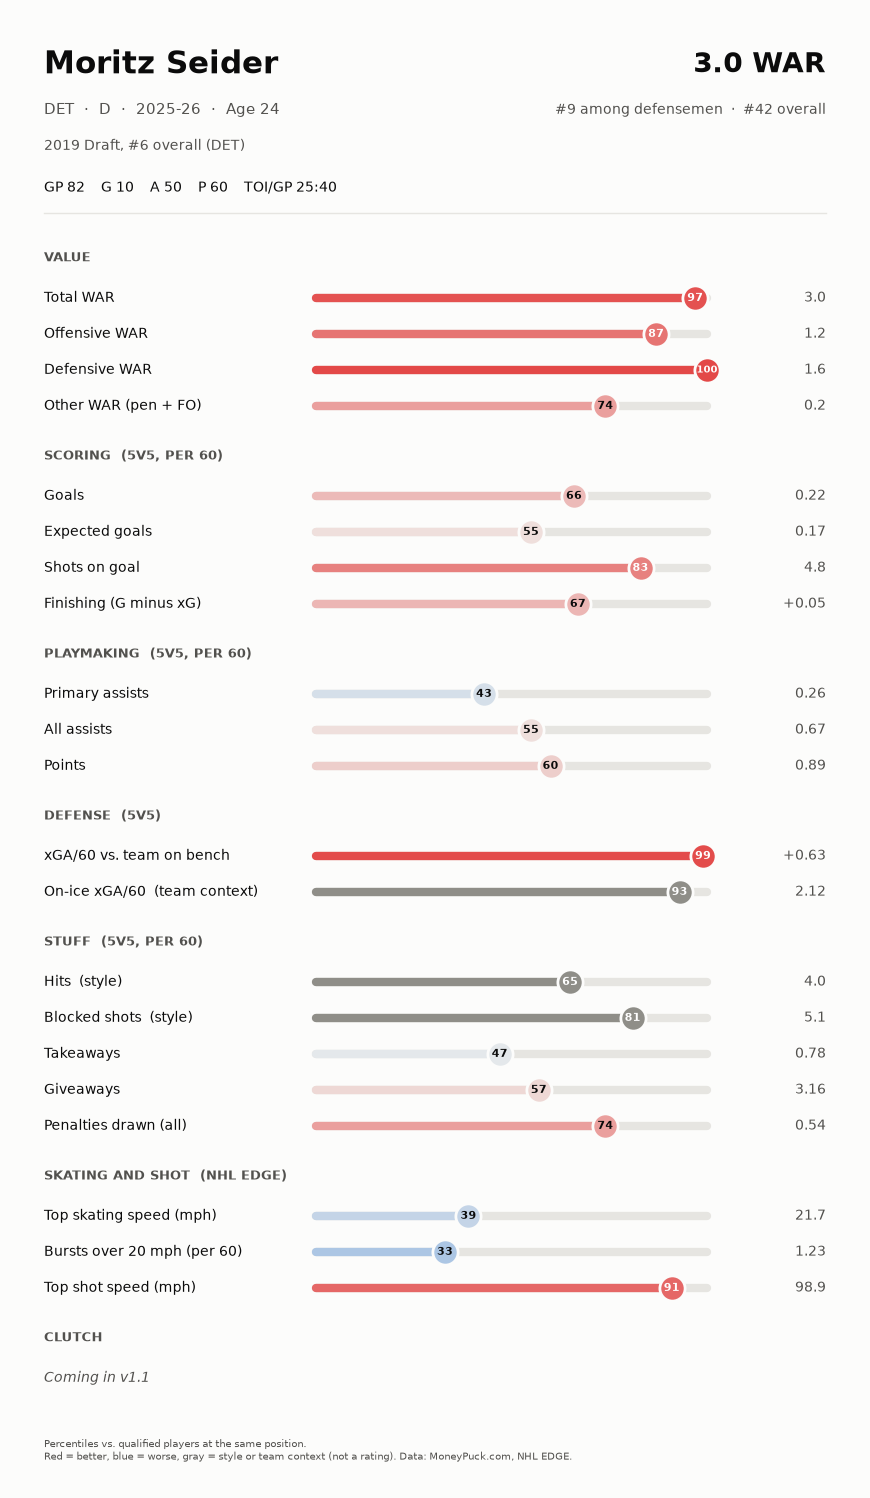

In [7]:
from player_card import draw_card

app = pd.read_csv(APP_PATH)
seider = app[app["name"] == "Moritz Seider"].iloc[0]
draw_card(seider, "2025-26", path=Path("../images/cards/seider_2025-26.png"));